# Binary Prediction with a Rainfall

## Getting Data Ready

In [2]:
# Importing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Load the datasets
train_df = pd.read_csv(r"/content/train.csv")
test_df = pd.read_csv(r"/content/test.csv")

In [6]:
train_df.head()

,id,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,sunshine,winddirection,windspeed,rainfall
0,0,1,1017.4,21.2,20.6,19.9,19.4,87.0,88.0,1.1,60.0,17.2,1
1,1,2,1019.5,16.2,16.9,15.8,15.4,95.0,91.0,0.0,50.0,21.9,1
2,2,3,1024.1,19.4,16.1,14.6,9.3,75.0,47.0,8.3,70.0,18.1,1
3,3,4,1013.4,18.1,17.8,16.9,16.8,95.0,95.0,0.0,60.0,35.6,1
4,4,5,1021.8,21.3,18.4,15.2,9.6,52.0,45.0,3.6,40.0,24.8,0


In [7]:
test_df.head()

,id,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,sunshine,winddirection,windspeed
0,2190,1,1019.5,17.5,15.8,12.7,14.9,96.0,99.0,0.0,50.0,24.3
1,2191,2,1016.5,17.5,16.5,15.8,15.1,97.0,99.0,0.0,50.0,35.3
2,2192,3,1023.9,11.2,10.4,9.4,8.9,86.0,96.0,0.0,40.0,16.9
3,2193,4,1022.9,20.6,17.3,15.2,9.5,75.0,45.0,7.1,20.0,50.6
4,2194,5,1022.2,16.1,13.8,6.4,4.3,68.0,49.0,9.2,20.0,19.4


In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2190 entries, 0 to 2189
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2190 non-null   int64  
 1   day            2190 non-null   int64  
 2   pressure       2190 non-null   float64
 3   maxtemp        2190 non-null   float64
 4   temparature    2190 non-null   float64
 5   mintemp        2190 non-null   float64
 6   dewpoint       2190 non-null   float64
 7   humidity       2190 non-null   float64
 8   cloud          2190 non-null   float64
 9   sunshine       2190 non-null   float64
 10  winddirection  2190 non-null   float64
 11  windspeed      2190 non-null   float64
 12  rainfall       2190 non-null   int64  
dtypes: float64(10), int64(3)
memory usage: 222.6 KB


In [9]:
train_df.describe()

,id,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,sunshine,winddirection,windspeed,rainfall
count,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000
mean,1094.500000,179.948402,1013.602146,26.365799,23.953059,22.170091,20.454566,82.036530,75.721918,3.744429,104.863151,21.804703,0.753425
std,632.342866,105.203592,5.655366,5.654330,5.222410,5.059120,5.288406,7.800654,18.026498,3.626327,80.002416,9.898659,0.431116
min,0.000000,1.000000,999.000000,10.400000,7.400000,4.000000,-0.300000,39.000000,2.000000,0.000000,10.000000,4.400000,0.000000
25%,547.250000,89.000000,1008.600000,21.300000,19.300000,17.700000,16.800000,77.000000,69.000000,0.400000,40.000000,14.125000,1.000000
50%,1094.500000,178.500000,1013.000000,27.800000,25.500000,23.850000,22.150000,82.000000,83.000000,2.400000,70.000000,20.500000,1.000000
75%,1641.750000,270.000000,1017.775000,31.200000,28.400000,26.400000,25.000000,88.000000,88.000000,6.800000,200.000000,27.900000,1.000000
max,2189.000000,365.000000,1034.600000,36.000000,31.500000,29.800000,26.700000,98.000000,100.000000,12.100000,300.000000,59.500000,1.000000


## Visualising Data

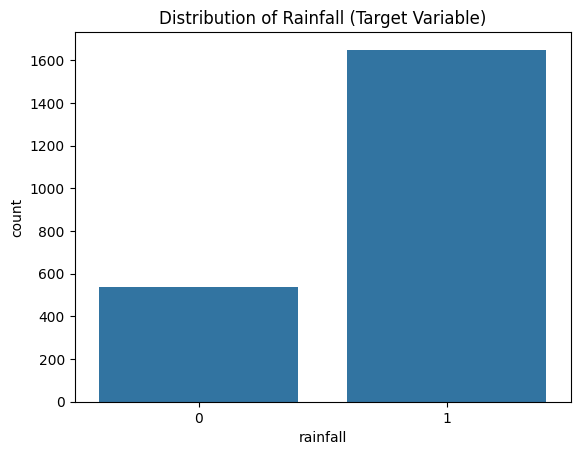

In [10]:
# Distribution of target variable (rainfall)
sns.countplot(x='rainfall', data=train_df)
plt.title('Distribution of Rainfall (Target Variable)')
plt.show()

#### Class Imbalance in rainfall(target)




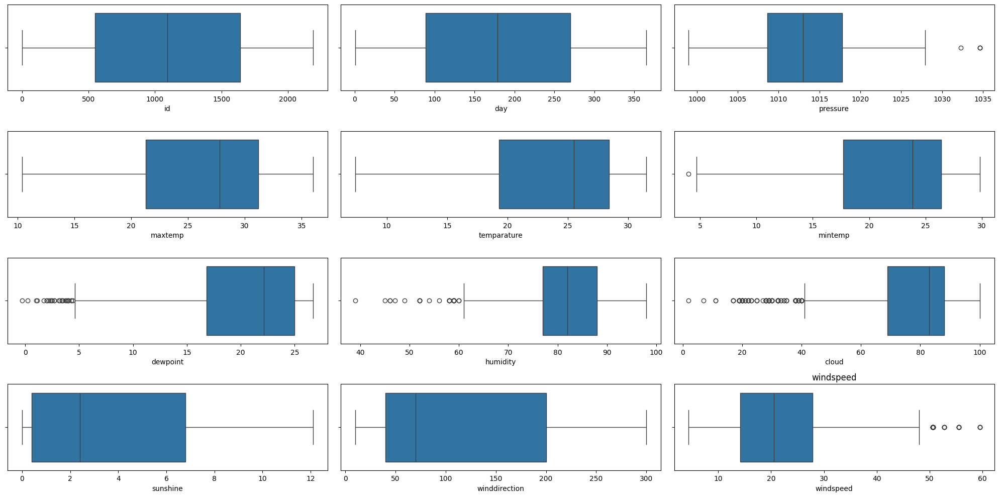

In [11]:
# Checking Outliers using Boxplot
fig,ax=plt.subplots(4,3,figsize=(20,10))
ax=ax.flatten()
i=0
for cols in train_df.columns:
    if i<len(ax):
        sns.boxplot(data=train_df,x=train_df[cols],ax=ax[i])
        plt.title(cols)
        i+=1
plt.tight_layout()
plt.show()

#### Some Outliers in cloud,humidity,dewpoint and windspeed

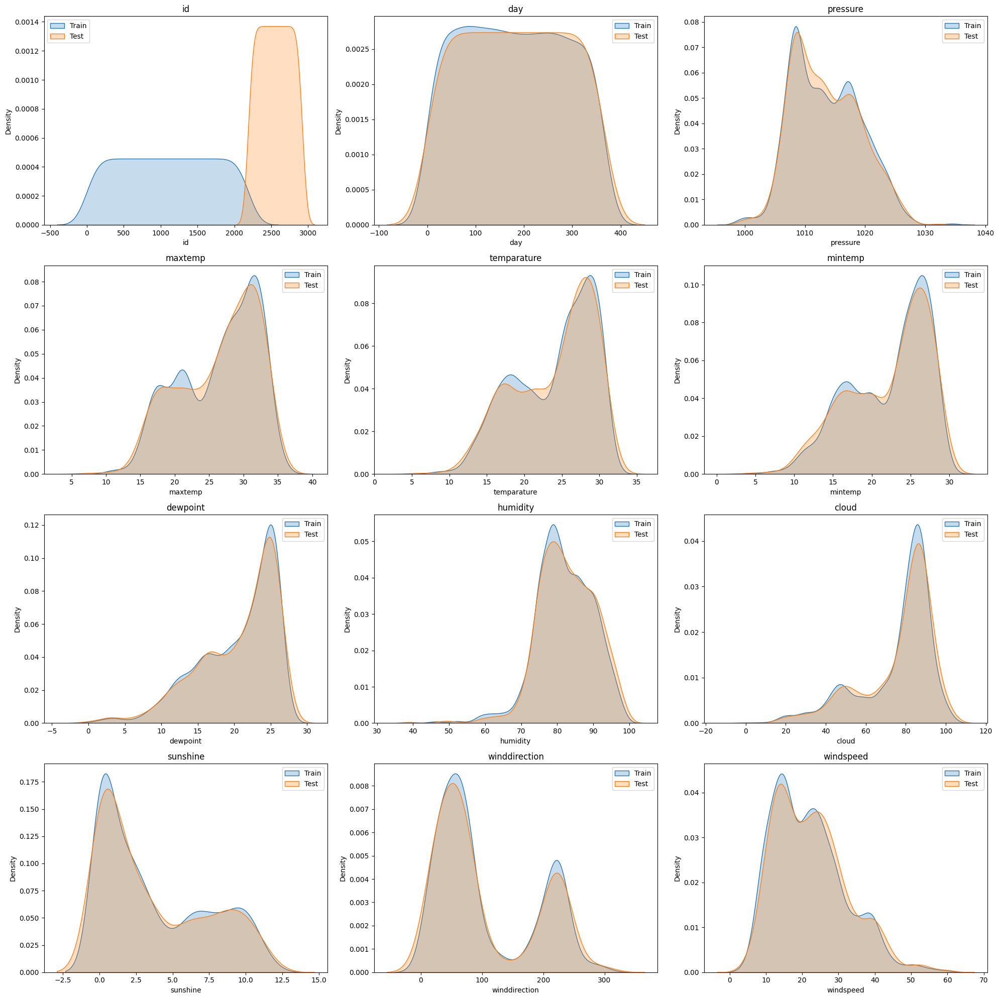

In [12]:
# Compare train and test data by looking at that distributions

fig, ax = plt.subplots(4, 3, figsize=(20, 20))
ax = ax.flatten()
i = 0
for col in train_df.columns:
    if col != 'rainfall':
        sns.kdeplot(data=train_df, x=col, ax=ax[i], label="Train", fill=True)
        sns.kdeplot(data=test_df, x=col, ax=ax[i], label="Test", fill=True)
        ax[i].set_title(col)
        ax[i].legend()
        i += 1
plt.tight_layout()

for j in range(i, len(ax)):
    ax[j].axis("off")

plt.show()

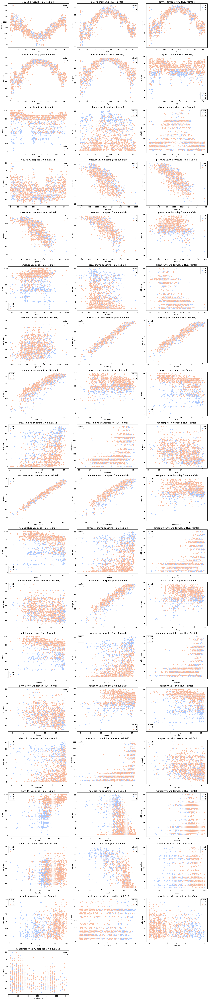

In [13]:
# Comparing columns based on rainfall
import itertools

features = ['day', 'pressure', 'maxtemp', 'temparature', 'mintemp', 'dewpoint',
            'humidity', 'cloud', 'sunshine', 'winddirection', 'windspeed']
pairs = list(itertools.combinations(features, 2))
n_cols = 3
n_rows = -(-len(pairs) // n_cols)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(20, 5 * n_rows))
axes = axes.flatten()
for i, (x, y) in enumerate(pairs):
    sns.scatterplot(data=train_df, x=x, y=y, hue='rainfall', palette='coolwarm', ax=axes[i])
    axes[i].set_title(f'{x} vs. {y} (Hue: Rainfall)', fontsize=14)
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## Data Preprocessing

In [14]:
# Checking datatypes
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2190 entries, 0 to 2189
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2190 non-null   int64  
 1   day            2190 non-null   int64  
 2   pressure       2190 non-null   float64
 3   maxtemp        2190 non-null   float64
 4   temparature    2190 non-null   float64
 5   mintemp        2190 non-null   float64
 6   dewpoint       2190 non-null   float64
 7   humidity       2190 non-null   float64
 8   cloud          2190 non-null   float64
 9   sunshine       2190 non-null   float64
 10  winddirection  2190 non-null   float64
 11  windspeed      2190 non-null   float64
 12  rainfall       2190 non-null   int64  
dtypes: float64(10), int64(3)
memory usage: 222.6 KB


#### All values are integer or float

In [15]:
# Checking null values
train_df.isna().sum()

,0
id,0
day,0
pressure,0
maxtemp,0
temparature,0
mintemp,0
dewpoint,0
humidity,0
cloud,0
sunshine,0


#### No missing values

## Feature Engineering

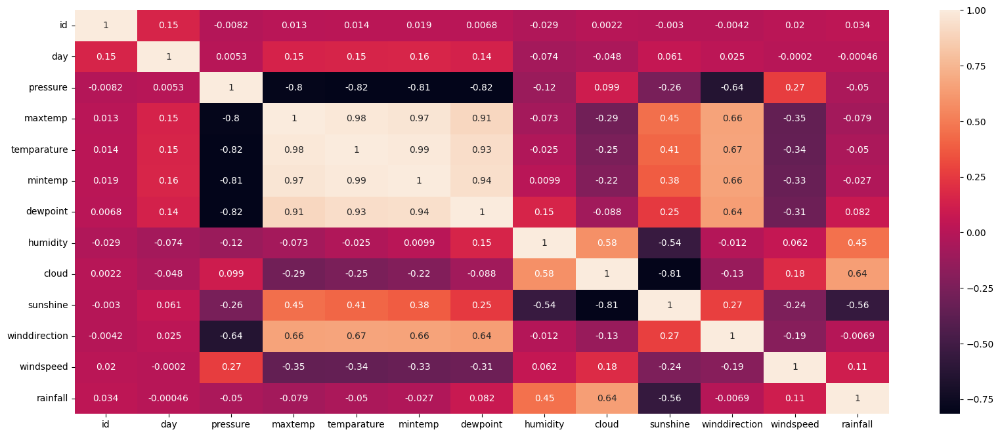

In [16]:
# Visualize correlation values
plt.figure(figsize=(20,8))
sns.heatmap(train_df.corr(),annot=True)
plt.show()

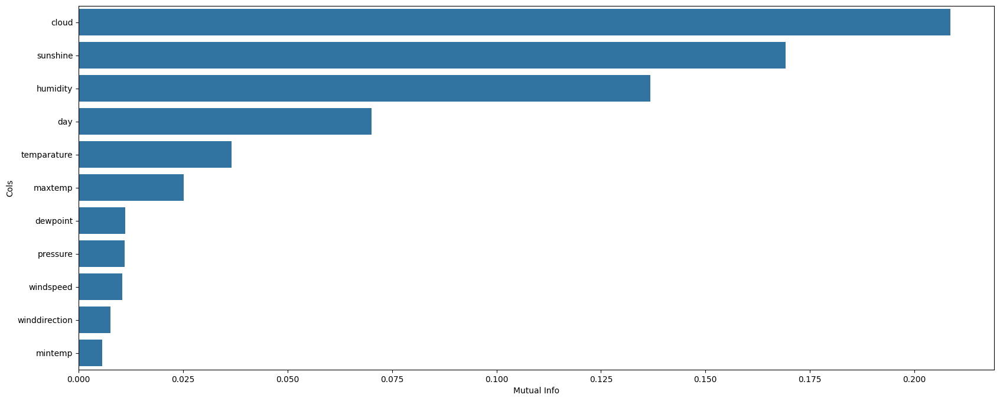

In [17]:
# Calculating dependency b/w features and target
from sklearn.feature_selection import mutual_info_classif

X = train_df.drop(columns=['id', 'rainfall'])
y = train_df['rainfall']
mi=mutual_info_classif(X,y)
mi_df=pd.DataFrame({"Cols":X.columns,'Mutual Info':mi})
mi_df.sort_values(ascending=False,inplace=True,by='Mutual Info')

plt.figure(figsize=(20,8))
sns.barplot(data=mi_df,x='Mutual Info',y='Cols')
plt.show()

In [18]:
# Adding some features
train_df['humidity_cloud_interaction'] = train_df['humidity'] * train_df['cloud']
train_df['humidity_sunshine_interaction'] = train_df['humidity'] * train_df['sunshine']
train_df['cloud_sunshine_ratio'] = train_df['cloud'] / (train_df['sunshine'] + 1e-5)
train_df['relative_dryness'] = 100 - train_df['humidity']
train_df['sunshine_percentage'] = train_df['sunshine'] / (train_df['sunshine'] + train_df['cloud'] + 1e-5)
train_df['weather_index'] = (0.4 * train_df['humidity']) + (0.3 * train_df['cloud']) - (0.3 * train_df['sunshine'])

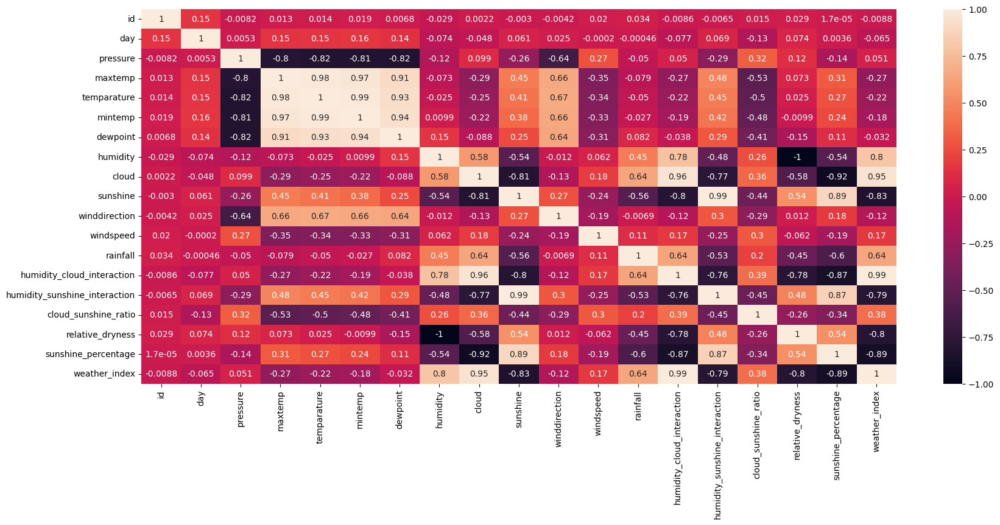

In [19]:
# Visualize correlation values for added features
plt.figure(figsize=(20,8))
sns.heatmap(train_df.corr(),annot=True)
plt.show()

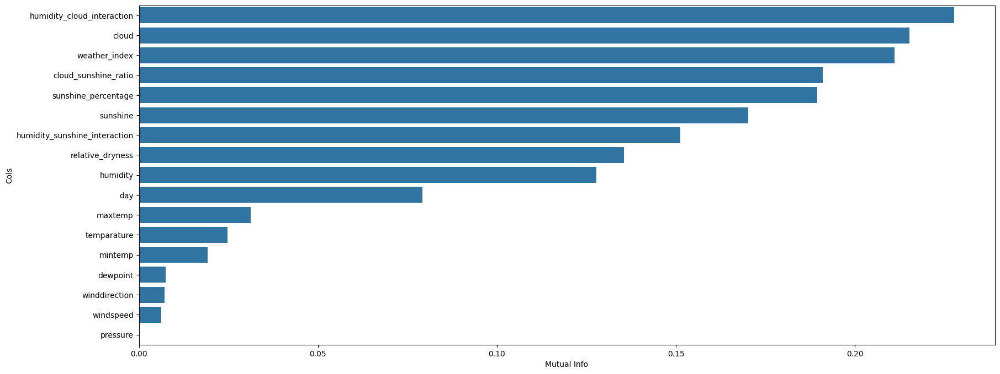

In [20]:
# Calculating dependency b/w features and target for added features
from sklearn.feature_selection import mutual_info_classif

X = train_df.drop(columns=['id', 'rainfall'])
y = train_df['rainfall']
mi=mutual_info_classif(X,y)
mi_df=pd.DataFrame({"Cols":X.columns,'Mutual Info':mi})
mi_df.sort_values(ascending=False,inplace=True,by='Mutual Info')

plt.figure(figsize=(20,8))
sns.barplot(data=mi_df,x='Mutual Info',y='Cols')
plt.show()

## Feature Selection

In [21]:
# Selecting features
selected_features = ['humidity_cloud_interaction', 'cloud', 'weather_index',
                    'sunshine_percentage', 'cloud_sunshine_ratio',
                    'humidity_sunshine_interaction', 'humidity',
                    'relative_dryness', 'maxtemp', 'mintemp']
X_train = train_df[selected_features]
y_train = train_df['rainfall']

In [22]:
# Scale the features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_train),columns=X_train.columns)

In [23]:
# Handling class imbalance using SMOTE
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_balanced, y_balanced = smote.fit_resample(X_scaled, y)
X_balanced = pd.DataFrame(X_balanced,columns=X_train.columns)
print(pd.Series(y_balanced).value_counts())

In [24]:
# Checking outliers
outliers = {}
factor=1.5
columns = ['humidity_cloud_interaction', 'cloud', 'weather_index',
                    'sunshine_percentage', 'cloud_sunshine_ratio',
                    'humidity_sunshine_interaction', 'humidity',
                    'relative_dryness', 'maxtemp', 'mintemp']
for col in columns:
    Q1 = X_balanced[col].quantile(0.25)
    Q3 = X_balanced[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - factor * IQR
    upper_bound = Q3 + factor * IQR
    outliers[col] = X_balanced[(X_balanced[col] < lower_bound) | (X_balanced[col] > upper_bound)].index
for col, idx in outliers.items():
    print(f"Outliers in {col}: {len(idx)} rows at indices {idx.tolist()}")

Outliers in humidity_cloud_interaction: 0 rows at indices []
Outliers in cloud: 0 rows at indices []
Outliers in weather_index: 0 rows at indices []
Outliers in sunshine_percentage: 27 rows at indices [381, 430, 747, 749, 752, 1112, 1113, 1250, 1371, 1844, 1892, 2209, 2304, 2305, 2449, 2450, 2488, 2515, 2523, 2548, 2608, 2655, 2742, 3180, 3212, 3230, 3289]
Outliers in cloud_sunshine_ratio: 618 rows at indices [1, 3, 5, 7, 8, 10, 11, 12, 13, 15, 18, 19, 20, 22, 23, 24, 26, 34, 35, 36, 39, 42, 43, 45, 47, 51, 52, 54, 55, 59, 60, 62, 65, 66, 67, 76, 78, 79, 82, 86, 89, 93, 95, 99, 105, 124, 129, 156, 176, 182, 204, 205, 207, 222, 233, 241, 269, 273, 276, 295, 296, 298, 303, 309, 316, 318, 324, 326, 328, 330, 332, 333, 339, 344, 345, 346, 348, 350, 351, 352, 353, 357, 359, 360, 361, 362, 363, 364, 365, 366, 368, 370, 371, 373, 374, 376, 377, 378, 382, 383, 385, 386, 390, 394, 396, 397, 398, 400, 401, 402, 403, 404, 408, 409, 410, 412, 415, 416, 417, 418, 419, 420, 421, 423, 426, 427, 428, 

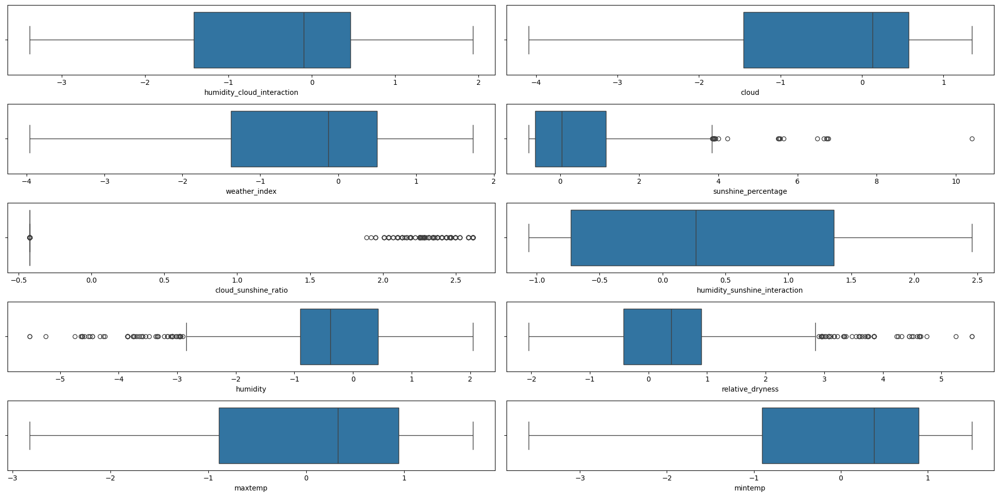

In [25]:
# Check boxplot before handling outliers
fig,ax=plt.subplots(5,2,figsize=(20,10))
ax=ax.flatten()
i=0
for cols in X_balanced.columns:
    if i<len(ax):
        sns.boxplot(data=X_balanced,x=X_balanced[cols],ax=ax[i])
        i+=1
plt.tight_layout()
plt.show()

In [26]:
# Handling Outliers
X_capped = X_balanced.copy()
outliers_column=['sunshine_percentage','humidity', 'relative_dryness']
lower_quantile=0.05
upper_quantile=0.95
for col in outliers_column:
    lower_bound = X_capped[col].quantile(lower_quantile)
    upper_bound = X_capped[col].quantile(upper_quantile)
    X_capped[col] = X_capped[col].clip(lower=lower_bound, upper=upper_bound)
# Droping 'cloud_sunshine_ratio' column because it have huge outliers
X_capped = X_capped.drop(labels=['cloud_sunshine_ratio'],axis=1)
y_capped = y_balanced.copy()

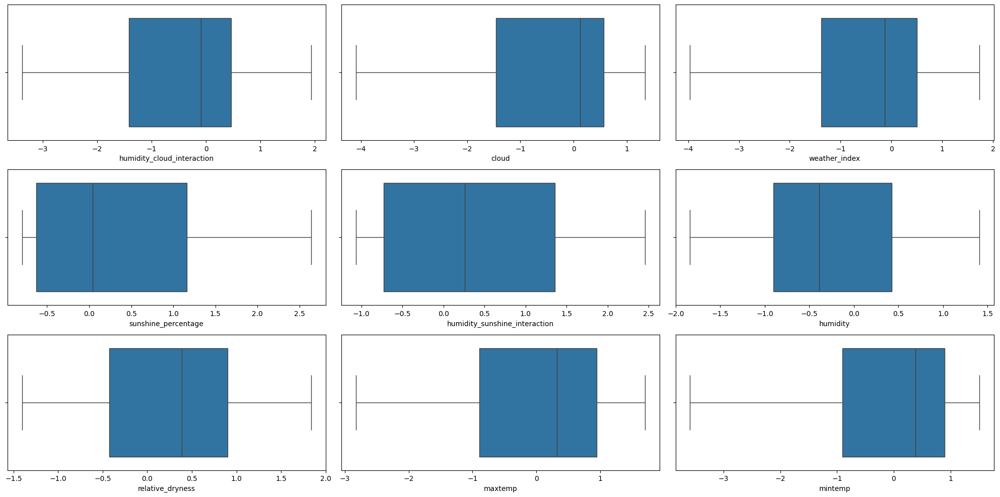

In [27]:
# Check boxplot after handling outliers
columns = ['humidity_cloud_interaction', 'cloud', 'weather_index',
           'sunshine_percentage', 'humidity_sunshine_interaction', 'humidity',
            'relative_dryness', 'maxtemp', 'mintemp']
fig,ax=plt.subplots(3,3,figsize=(20,10))
ax=ax.flatten()
i=0
for cols in X_capped.columns:
    if i<len(ax):
        sns.boxplot(data=X_capped,x=X_capped[cols],ax=ax[i])
        i+=1
plt.tight_layout()
plt.show()

## Modelling

In [28]:
# Split the cleaned data
from sklearn.model_selection import train_test_split
X_cap_train, X_cap_val, y_cap_train, y_cap_val = train_test_split(X_capped, y_capped, test_size=0.2, random_state=42, stratify=y_capped)

### 1. RandomForestClassifier

In [37]:
# Train model using Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
rf = RandomForestClassifier(random_state=30, class_weight='balanced', n_estimators=200, max_depth=20, min_samples_split=5)
rf.fit(X_cap_train, y_cap_train)
y_pred = rf.predict(X_cap_val)
accuracy = accuracy_score(y_cap_val, y_pred)
roc = roc_auc_score(y_cap_val, y_pred)
accuracy,roc

(0.853030303030303, np.float64(0.853030303030303))

In [32]:
# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=30, class_weight='balanced'), param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(X_cap_train, y_cap_train)

print("\nBest Parameters:", grid_search.best_params_)
best_rf = grid_search.best_estimator_
y_pred_rf = best_rf.predict(X_cap_val)
accuracy_score(y_cap_val, y_pred_rf)*100

Fitting 5 folds for each of 108 candidates, totalling 540 fits

Best Parameters: {'max_depth': 30, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


85.3030303030303

### 2. XGBClassifier

In [38]:
# Train model using XGB Classifier
from xgboost import XGBClassifier
xgb = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb.fit(X_cap_train, y_cap_train);
y_pred = xgb.predict(X_cap_val)
accuracy = accuracy_score(y_cap_val, y_pred)
roc = roc_auc_score(y_cap_val, y_pred)
accuracy,roc

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [18:13:34] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


(0.8545454545454545, np.float64(0.8545454545454545))

In [40]:
# Hyperparameter tuning
param_grid = {
    'n_estimators': [100, 200, 300, 500],  # More trees for better learning
    'max_depth': [3, 5, 7, 10],  # Shallower depths to prevent overfitting
    'max_leaves': [0, 31, 63, 127],  # 0 means no limit; others control tree complexity
    'learning_rate': [0.01, 0.05, 0.1, 0.3],  # Range from conservative to aggressive
    'grow_policy': ['depthwise', 'lossguide'],  # Different tree growth strategies
    'min_child_weight': [1, 3, 5, 7],  # Higher values for regularization
    'booster': ['gbtree', 'dart'],  # Test tree-based and DART (dropout) boosters
    'tree_method': ['auto', 'hist'],  # 'hist' for faster training, 'auto' for default
    'subsample': [0.6, 0.8, 1.0],  # Subsampling to prevent overfitting
    'max_delta_step': [0, 1, 5],  # 0 means no constraint; useful for imbalanced data
    'sampling_method': ['uniform', 'gradient_based']  # Different sampling strategies
}
grid_search = GridSearchCV(xgb, param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=2)
grid_search.fit(X_cap_train, y_cap_train)

print("\nBest Parameters:", grid_search.best_params_)
best_xgb = grid_search.best_estimator_
y_pred_xgb = best_xgb.predict(X_cap_val)
accuracy_score(y_cap_val, y_pred_rf)*100

Fitting 5 folds for each of 147456 candidates, totalling 737280 fits


KeyboardInterrupt: 

### 3. Combining XGBClassifier and RandomForestClassifier

In [39]:
from sklearn.ensemble import VotingClassifier
voting_clf = VotingClassifier(estimators=[
    ('xgb', xgb),
    ('rf', rf)
], voting='soft')
voting_clf.fit(X_cap_train, y_cap_train)
y_pred = voting_clf.predict(X_cap_val)
accuracy = accuracy_score(y_cap_val, y_pred)
roc = roc_auc_score(y_cap_val, y_pred)
accuracy,roc

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [18:13:43] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


(0.8606060606060606, np.float64(0.8606060606060606))

### 4. CNN Model

In [29]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from tensorflow.keras.layers import Add, Input
from tensorflow.keras.models import Model

X_train_reshaped = np.array(X_cap_train).reshape(X_cap_train.shape[0], X_cap_train.shape[1], 1)
y_train_reshaped = y_cap_train.copy()
X_val_reshaped = np.array(X_cap_val).reshape(X_cap_val.shape[0], X_cap_val.shape[1], 1)
y_val_reshaped = y_cap_val.copy()

# Define the modified CNN model with residual connections
def build_cnn_model(input_shape):
    # Functional API for residual connections
    inputs = Input(shape=input_shape)

    # First Conv1D block
    x = Conv1D(filters=32, kernel_size=3, activation='relu', padding='same',
               kernel_regularizer=l2(0.005))(inputs)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)

    # Second Conv1D block with residual connection
    residual = x
    x = Conv1D(filters=64, kernel_size=3, activation='relu', padding='same',
               kernel_regularizer=l2(0.005))(x)
    x = BatchNormalization()(x)
    x = Conv1D(filters=64, kernel_size=3, activation='relu', padding='same',
               kernel_regularizer=l2(0.005))(x)
    x = BatchNormalization()(x)
    # Adjust residual shape if needed
    residual = Conv1D(filters=64, kernel_size=1, padding='same')(residual)
    x = Add()([x, residual])
    x = MaxPooling1D(pool_size=2)(x)

    # Third Conv1D block
    x = Conv1D(filters=128, kernel_size=3, activation='relu', padding='same',
               kernel_regularizer=l2(0.005))(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)

    # Flatten and Dense layers
    x = Flatten()(x)
    x = Dense(128, activation='relu', kernel_regularizer=l2(0.005))(x)
    x = Dropout(0.4)(x)  # Reduced dropout
    x = Dense(64, activation='relu', kernel_regularizer=l2(0.005))(x)
    x = Dropout(0.3)(x)  # Reduced dropout

    # Output layer
    outputs = Dense(1, activation='sigmoid')(x)

    # Build model
    model = Model(inputs, outputs)

    # Compile the model
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Input shape: (n_features, 1) = (10, 1)
input_shape = (X_train_reshaped.shape[1], 1)
cnn_model = build_cnn_model(input_shape)

# Summary of the model
cnn_model.summary()

# Define callbacks
early_stopping = EarlyStopping(monitor='val_accuracy', patience=20, restore_best_weights=True, mode='max')
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6, verbose=1)

# Train the model
history = cnn_model.fit(X_train_reshaped, y_train_reshaped,
                        epochs=400,
                        batch_size=32,
                        validation_data=(X_val_reshaped, y_val_reshaped),
                        callbacks=[early_stopping, reduce_lr],
                        verbose=1)

# Evaluate on training data
train_loss, train_accuracy = cnn_model.evaluate(X_train_reshaped, y_train_reshaped, verbose=0,)
print(f"Training Accuracy: {train_accuracy * 100:.2f}%")

# Evaluate on validation data
val_loss, val_accuracy = cnn_model.evaluate(X_val_reshaped, y_val_reshaped, verbose=0)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 9, 1)           │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d (Conv1D)           │ (None, 9, 32)          │            128 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 9, 32)          │            128 │ conv1d[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling1d             │ (None, 4, 32)          │              0 │ batch_normalization[0… │
│ (MaxPooling1D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_1 (Conv1D)         │ (None, 4, 64)          │          6,208 │ max_pooling1d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 4, 64)          │            256 │ conv1d_1[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_2 (Conv1D)         │ (None, 4, 64)          │         12,352 │ batch_normalization_1… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 4, 64)          │            256 │ conv1d_2[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_3 (Conv1D)         │ (None, 4, 64)          │          2,112 │ max_pooling1d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add (Add)                 │ (None, 4, 64)          │              0 │ batch_normalization_2… │
│                           │                        │                │ conv1d_3[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling1d_1           │ (None, 2, 64)          │              0 │ add[0][0]              │
│ (MaxPooling1D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1d_4 (Conv1D)         │ (None, 2, 128)         │         24,704 │ max_pooling1d_1[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_3     │ (None, 2, 128)         │            512 │ conv1d_4[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling1d_2           │ (None, 1, 128)         │              0 │ batch_normalization_3… │
│ (MaxPooling1D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ flatten (Flatten)         │ (None, 128)            │              0 │ max_pooling1d_2[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense (Dense)        

 Total params: 71,489 (279.25 KB)

 Trainable params: 70,913 (277.00 KB)

 Non-trainable params: 576 (2.25 KB)

Epoch 1/400
83/83 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.7665 - loss: 2.4763 - val_accuracy: 0.6424 - val_loss: 2.2960 - learning_rate: 0.0010
Epoch 2/400
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8252 - loss: 1.9824 - val_accuracy: 0.5909 - val_loss: 1.9340 - learning_rate: 0.0010
Epoch 3/400
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8308 - loss: 1.6220 - val_accuracy: 0.6742 - val_loss: 1.6067 - learning_rate: 0.0010
Epoch 4/400
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8377 - loss: 1.3604 - val_accuracy: 0.7500 - val_loss: 1.3283 - learning_rate: 0.0010
Epoch 5/400
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8448 - loss: 1.1171 - val_accuracy: 0.7909 - val_loss: 1.1064 - learning_rate: 0.0010
Epoch 6/400
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8499 - loss: 0.9683 - val_accuracy: 0.7939 - val_loss: 0.9498 - learning_rate: 0.0010
Epoch 7/400
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8479 - loss: 0.8307 - val

### 5. MLP Model

In [30]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

# Define the MLP model
def build_mlp_model(input_shape):
    model = Sequential([
        Dense(256, activation='relu', input_shape=input_shape, kernel_regularizer=l2(0.01)),
        Dropout(0.5),
        Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.3),
        Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.2),
        Dense(32, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.2),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Input shape: (n_features,) = (10,)
mlp_model = build_mlp_model(input_shape=(X_train_reshaped.shape[1],))

# Define callbacks
early_stopping = EarlyStopping(monitor='val_accuracy', patience=20, restore_best_weights=True, mode='max')
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6, verbose=1)

# Train the model
history = mlp_model.fit(X_train_reshaped, y_train_reshaped,
                        epochs=200,
                        batch_size=32,
                        validation_data=(X_val_reshaped, y_val_reshaped),
                        callbacks=[early_stopping, reduce_lr],
                        verbose=1)

# Evaluate
train_loss, train_accuracy = mlp_model.evaluate(X_train_reshaped, y_train_reshaped, verbose=0)
print(f"MLP Training Accuracy: {train_accuracy * 100:.2f}%")
val_loss, val_accuracy = mlp_model.evaluate(X_val_reshaped, y_val_reshaped, verbose=0)
print(f"MLP Validation Accuracy: {val_accuracy * 100:.2f}%")


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/200
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7451 - loss: 2.9653 - val_accuracy: 0.7939 - val_loss: 1.3727 - learning_rate: 0.0010
Epoch 2/200
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8192 - loss: 1.1614 - val_accuracy: 0.8000 - val_loss: 0.7677 - learning_rate: 0.0010
Epoch 3/200
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8342 - loss: 0.6789 - val_accuracy: 0.8015 - val_loss: 0.6075 - learning_rate: 0.0010
Epoch 4/200
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8217 - loss: 0.5610 - val_accuracy: 0.8015 - val_loss: 0.5456 - learning_rate: 0.0010
Epoch 5/200
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8304 - loss: 0.5020 - val_accuracy: 0.8000 - val_loss: 0.5208 - learning_rate: 0.0010
Epoch 6/200
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8367 - loss: 0.4854 - val_accuracy: 0.7985 - val_loss: 0.5127 - learning_rate: 0.0010
Epoch 7/200
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8327 - loss: 0.4761 - val_acc

### 5. Combining RandomForestClassifier, XGBClassifier, CNN and MLP

In [36]:
# Ensemble predictions
cnn_pred = cnn_model.predict(X_val_reshaped).flatten()
rf_pred = rf.predict_proba(X_cap_val)[:, 1]
xgb_pred = xgb.predict_proba(X_cap_val)[:, 1]
mlp_pred = mlp_model.predict(X_cap_val).flatten()

# Average predictions
ensemble_pred = (cnn_pred + rf_pred + xgb_pred + mlp_pred) / 4
ensemble_pred_binary = (ensemble_pred > 0.5).astype(int)
ensemble_accuracy = accuracy_score(y_cap_val, ensemble_pred_binary)
print(f"Ensemble Validation Accuracy: {ensemble_accuracy * 100:.2f}%")

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
Ensemble Validation Accuracy: 85.61%
